In [142]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
import statsmodels.stats.multicomp as mc
from IPython.display import display
import networkx as nx
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator
from pgmpy.inference import VariableElimination

## 1. Leitura dos dados

In [143]:
PASTA_PRECIP = os.path.join("..", "DATA", "CSV_regioes")   # precipitação
PASTA_ACUDES = os.path.join("..", "DATA", "CSV_acudes")    # volume dos açudes

def ler_pasta(pasta, sep=";", **kwargs):
    lista = []
    for nome in sorted(os.listdir(pasta)):
        if nome.lower().endswith(".csv"):
            df = pd.read_csv(os.path.join(pasta, nome), sep=sep, **kwargs)
            df["arquivo"] = os.path.splitext(nome)[0]
            lista.append(df)
    if not lista:
        raise FileNotFoundError(f"Nenhum CSV em: {pasta}")
    return lista

df_1 = pd.concat(ler_pasta(PASTA_PRECIP, decimal="."), ignore_index=True)
df_2 = pd.concat(ler_pasta(PASTA_ACUDES, decimal=","), ignore_index=True).rename(columns={"arquivo": "acude"})

display(df_1.head())
display(df_2.head())
print(df_1.dtypes, "\n")
print(df_2.dtypes)

,data,lat,lon,precip_mm,municipio,estado,uf,regiao,arquivo
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste,precipitacao_2006_com_local
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste,precipitacao_2006_com_local
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste,precipitacao_2006_com_local


,DateTime,Volume (hm³),acude
0,2006-01-01 00:00:00,42.59,reserv_atalho
1,2006-01-02 00:00:00,42.59,reserv_atalho
2,2006-01-03 00:00:00,NaN,reserv_atalho
3,2006-01-04 00:00:00,NaN,reserv_atalho
4,2006-01-05 00:00:00,NaN,reserv_atalho


data          object
lat          float64
lon          float64
precip_mm    float64
municipio     object
estado        object
uf            object
regiao        object
arquivo       object
dtype: object 

DateTime         object
Volume (hm³)    float64
acude            object
dtype: object


## 2. Pré-processamento dos açudes

- `pct`: volume em % da capacidade máxima (limitado a 100%).
- `classe_acude`: classe ordinal do volume (≤10% muito crítico, ≤30% crítico, ≤50% alerta, ≤70% confortável, >70% muito confortável).
- `status_alerta`: **0** = muito crítico ou crítico (≤30%), **1** = acima de 30%.

In [144]:
# Padroniza o nome do açude (o arquivo pode vir como 'olho_dagua' ou 'olhodgua')
df_2["acude"] = df_2["acude"].replace({"reserv_olho_dagua": "reserv_olhodgua"})

capacidade = {            # hm³
    "reserv_olhodgua":   19.210,
    "reserv_quixabinha": 31.780,
    "reserv_atalho":     72.550,
    "reserv_rosario":    47.220,
}

df_2["capacidade_maxima"] = df_2["acude"].map(capacidade).astype(float)
sem_capacidade = df_2.loc[df_2["capacidade_maxima"].isna(), "acude"].unique()
if len(sem_capacidade):
    print("ATENÇÃO: açudes sem capacidade cadastrada:", sem_capacidade)

df_2["pct"] = (df_2["Volume (hm³)"] / df_2["capacidade_maxima"] * 100).clip(upper=100)
pct = df_2["pct"]

condicoes = [
    (pct >= 0)  & (pct <= 10),
    (pct > 10)  & (pct <= 30),
    (pct > 30)  & (pct <= 50),
    (pct > 50)  & (pct <= 70),
    (pct > 70)  & (pct <= 100),
]
rotulos = ["muito_critico", "critico", "alerta", "confortavel", "muito_confortavel"]
df_2["classe_acude"] = np.select(condicoes, rotulos, default="sem_classe")
df_2.loc[pct.isna() | (df_2["classe_acude"] == "sem_classe"), "classe_acude"] = np.nan

# 0 = muito crítico/crítico (<=30%) | 1 = acima de 30%; NA onde não há volume
df_2["status_alerta"] = (pct > 30).astype("Int64").where(pct.notna())

print(df_2["classe_acude"].value_counts(dropna=False))
print(df_2["status_alerta"].value_counts(dropna=False))

classe_acude
muito_confortavel    8736
critico              6812
alerta               5039
confortavel          3786
NaN                  3142
muito_critico        2796
Name: count, dtype: int64
status_alerta
1       17561
0        9608
<NA>     3142
Name: count, dtype: Int64


## 3. Integração: açude × ponto de precipitação mais próximo

Cada açude é ligado ao ponto de chuva mais próximo (distância de Haversine, raio máximo de 50 km) e os dados são unidos pela data.

In [145]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Distância em km entre pontos (fórmula de Haversine)."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

coordenadas_acudes = pd.DataFrame({
    "acude":     ["reserv_atalho", "reserv_rosario", "reserv_olhodgua", "reserv_quixabinha"],
    "lat_acude": [-8.75, -6.75, -6.25, -7.25],
    "lon_acude": [-38.25, -39.25, -36.25, -38.75],
})
RAIO_MAXIMO_KM = 50.0

# chave de data em texto, igual nas duas tabelas
df_1["data_str"] = pd.to_datetime(df_1["data"]).dt.strftime("%Y-%m-%d")
df_2["data_str"] = pd.to_datetime(df_2["DateTime"]).dt.strftime("%Y-%m-%d")

# remove linhas repetidas de precipitação (mesma data e mesmo ponto)
antes = len(df_1)
df_1 = df_1.drop_duplicates(subset=["data_str", "lat", "lon"]).reset_index(drop=True)
print(f"Linhas repetidas removidas em df_1: {antes - len(df_1)}")

pontos = df_1[["lat", "lon"]].drop_duplicates().reset_index(drop=True)
mapeamento = []
for _, ac in coordenadas_acudes.iterrows():
    dist = haversine_km(ac["lat_acude"], ac["lon_acude"], pontos["lat"], pontos["lon"])
    i = dist.idxmin()
    if dist.loc[i] <= RAIO_MAXIMO_KM:
        mapeamento.append({
            "acude": ac["acude"],
            "lat_precip_mais_proxima": pontos.loc[i, "lat"],
            "lon_precip_mais_proxima": pontos.loc[i, "lon"],
            "distancia_km": dist.loc[i],
        })
    else:
        print(f"Açude '{ac['acude']}' ignorado: ponto de chuva mais próximo a {dist.loc[i]:.1f} km (limite {RAIO_MAXIMO_KM} km).")

df_map = pd.DataFrame(mapeamento)
if df_map.empty:
    raise ValueError("Nenhum açude atendeu ao critério de distância.")

df_2_geo = df_2.merge(df_map, on="acude", how="inner")
df_unificado = df_2_geo.merge(
    df_1,
    left_on=["data_str", "lat_precip_mais_proxima", "lon_precip_mais_proxima"],
    right_on=["data_str", "lat", "lon"],
    how="inner",
)
print(f"Registros válidos (raio de {RAIO_MAXIMO_KM} km): {len(df_unificado)}")
print(df_unificado["acude"].value_counts())

df_final = df_unificado.rename(columns={
    "DateTime": "Data",
    "Volume (hm³)": "volume",
    "precip_mm": "precipitação",
    "classe_acude": "classe_volume_acude",
    "status_alerta": "bin_status_alerta",
})
cols = ["Data", "acude", "municipio", "estado", "volume", "pct",
        "precipitação", "classe_volume_acude", "bin_status_alerta"]
df_final = df_final[[c for c in cols if c in df_final.columns]].copy()

print(df_final.dtypes)
print(df_final.isna().sum())
display(df_final.head())

Linhas repetidas removidas em df_1: 198
Açude 'reserv_atalho' ignorado: ponto de chuva mais próximo a 111.2 km (limite 50.0 km).
Açude 'reserv_olhodgua' ignorado: ponto de chuva mais próximo a 110.5 km (limite 50.0 km).
Registros válidos (raio de 50.0 km): 15154
acude
reserv_quixabinha    7577
reserv_rosario       7577
Name: count, dtype: int64
Data                    object
acude                   object
municipio               object
estado                  object
volume                 float64
pct                    float64
precipitação           float64
classe_volume_acude     object
bin_status_alerta        Int64
dtype: object
Data                      0
acude                     0
municipio                 0
estado                    0
volume                 1417
pct                    1417
precipitação              2
classe_volume_acude    1417
bin_status_alerta      1417
dtype: int64


,Data,acude,municipio,estado,volume,pct,precipitação,classe_volume_acude,bin_status_alerta
0,2006-01-01 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.58,23.851479,1.460885,critico,0
1,2006-01-02 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.58,23.851479,44.768280,critico,0
2,2006-01-03 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.57,23.820013,18.526501,critico,0
3,2006-01-04 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.57,23.820013,0.000000,critico,0
4,2006-01-05 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.57,23.820013,0.000000,critico,0


---
## QUESTÃO 2: teste de associação (nos dados originais)

**Natureza das variáveis**
- `precipitação` (mm): **quantitativa contínua** (preditora).
- `classe_volume_acude`: **qualitativa ordinal** (dependente).

Como a preditora é quantitativa e a dependente é qualitativa, compara-se a precipitação entre os grupos da qualitativa:

1. Descritiva e boxplot por grupo.
2. **ANOVA** (H0: a média da precipitação é igual em todas as classes de volume).
3. Pressupostos: **normalidade dos resíduos** (KS; H0: normais) e **homogeneidade de variâncias** (Levene; H0: variâncias iguais).
4. Se algum pressuposto for rejeitado, usa-se o **Kruskal-Wallis** (H0: a localização da precipitação é a mesma em todos os grupos).

Critério de decisão: α = 5%.

Inicialmente foi avaliada a associação entre a variável quantitativa precipitação (mm) e a variável dependente classe do volume do açude. Como a variável explicativa é quantitativa e a variável resposta é qualitativa ordinal, foi analisado se os valores de precipitação diferiam entre as classes de volume do reservatório.


Antes da aplicação da ANOVA, seus pressupostos foram verificados. O teste de Kolmogorov-Smirnov indicou rejeição da hipótese de normalidade dos resíduos (p < 0,05), enquanto o teste de Levene rejeitou a hipótese de homogeneidade das variâncias (p < 0,05). Dessa forma, os pressupostos necessários para utilização da ANOVA não foram atendidos.


Em razão dessas violações, foi aplicado o teste não paramétrico de Kruskal-Wallis. O resultado obtido (H = 64,25; p = 3,699×10⁻¹³) permitiu rejeitar a hipótese nula de igualdade das distribuições de precipitação entre as classes de volume dos açudes. Assim, conclui-se que existe associação estatisticamente significativa entre precipitação e situação de armazenamento dos reservatórios.


Observa-se ainda que a classe "alerta" apresentou a maior média de precipitação (31,30 mm), enquanto as classes "muito crítico" e "crítico" apresentaram médias menores (19,76 mm e 21,92 mm, respectivamente). Esse resultado sugere que volumes mais elevados tendem a estar associados à ocorrência de maiores índices pluviométricos.


Entretanto, o tamanho de efeito obtido (ε² = 0,0047) foi muito baixo, indicando que a precipitação, apesar de estatisticamente associada ao volume do açude, possui influência limitada quando analisada isoladamente. Isso sugere a existência de outros fatores importantes na determinação do volume armazenado, como o volume anterior do reservatório, evaporação, consumo hídrico e características próprias de cada açude.


Portanto, conclui-se que a precipitação apresenta associação significativa com a variável dependente, justificando sua utilização como variável preditora na Rede Bayesiana construída nas etapas seguintes do trabalho.


n = 13735
                      count   mean    std  min  25%   50%    75%     max
classe_volume_acude                                                     
muito_critico        1541.0  19.76  62.70  0.0  0.0  0.00   5.53  963.00
critico              4860.0  21.92  60.84  0.0  0.0  0.00   8.25  749.25
alerta               1669.0  31.30  75.80  0.0  0.0  0.27  20.34  731.16
confortavel          1428.0  26.65  75.07  0.0  0.0  0.00   9.94  722.01
muito_confortavel    4237.0  24.38  65.01  0.0  0.0  0.00  10.87  774.45


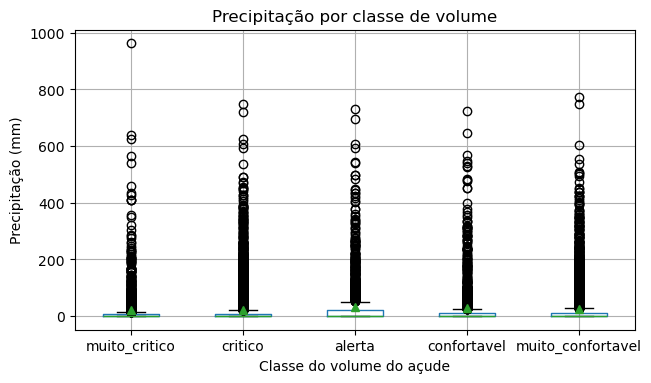

In [146]:
quanti, quali = "precipitação", "classe_volume_acude"
ALPHA = 0.05

ordem = ["muito_critico", "critico", "alerta", "confortavel", "muito_confortavel"]
ordem = [o for o in ordem if o in df_final[quali].dropna().unique()]

dq = df_final[[quanti, quali]].dropna().copy()
dq[quali] = pd.Categorical(dq[quali], categories=ordem, ordered=True)
print("n =", len(dq))

# 1) Descritiva por grupo
print(dq.groupby(quali, observed=True)[quanti].describe().round(2))

ax = dq.boxplot(column=quanti, by=quali, figsize=(7, 4), showmeans=True)
ax.set_ylabel("Precipitação (mm)")
ax.set_xlabel("Classe do volume do açude")
plt.suptitle("")
plt.title("Precipitação por classe de volume")
plt.show()

    O boxplot, acima, mostra que a precipitação apresenta grande variabilidade em todas as classes de volume dos açudes, com a presença de diversos valores extremos associados a eventos de chuvas intensas. Observa-se que as medianas de precipitação são muito baixas, próximas de zero na maioria das classes, indicando predominância de dias com pouca ou nenhuma chuva. Apesar de as classes com maiores volumes apresentarem, em geral, médias de precipitação mais elevadas, existe uma forte sobreposição entre os grupos, sugerindo que a precipitação isoladamente não é suficiente para explicar as diferenças observadas no volume dos reservatórios. Essa evidência visual é coerente com o resultado do teste de Kruskal-Wallis, que apontou associação estatisticamente significativa entre as variáveis, porém com tamanho de efeito reduzido, indicando que outros fatores além da chuva também influenciam o armazenamento de água nos açudes.

In [147]:
# 2) ANOVA
d_aov = dq.rename(columns={quanti: "precip", quali: "classe"})
model = ols("precip ~ C(classe)", data=d_aov).fit()
aov_table = sm.stats.anova_lm(model, typ=2)
print(aov_table, "\n")

# 3a) Normalidade dos resíduos (H0: normais)
ks = stats.kstest(model.resid, stats.norm.cdf, args=(model.resid.mean(), model.resid.std()))
print("KS resíduos:", ks)

# 3b) Homogeneidade de variâncias (H0: variâncias iguais)
grupos = [g[quanti].dropna() for _, g in dq.groupby(quali, observed=True)]
lev = stats.levene(*grupos)
print("Levene:", lev)

normal = ks.pvalue >= ALPHA
homogeneo = lev.pvalue >= ALPHA
print("\nNormalidade dos resíduos:", "não rejeitada" if normal else "REJEITADA")
print("Homogeneidade de variâncias:", "não rejeitada" if homogeneo else "REJEITADA")
usar_anova = normal and homogeneo
print("Teste adequado:", "ANOVA" if usar_anova else "Kruskal-Wallis")

                 sum_sq       df         F        PR(>F)
C(classe)  1.484196e+05      4.0  8.552396  6.878519e-07
Residual   5.956813e+07  13730.0       NaN           NaN 

KS resíduos: KstestResult(statistic=np.float64(0.333254515808197), pvalue=np.float64(0.0), statistic_location=np.float64(-11.070376365705837), statistic_sign=np.int8(1))
Levene: LeveneResult(statistic=np.float64(8.551032917385623), pvalue=np.float64(6.896212765370673e-07))

Normalidade dos resíduos: REJEITADA
Homogeneidade de variâncias: REJEITADA
Teste adequado: Kruskal-Wallis


In [148]:
# 4) Kruskal-Wallis
H, p_kw = stats.kruskal(*grupos)
n = sum(len(g) for g in grupos)
eps2 = H / (n - 1)   # tamanho de efeito: ~0,01 pequeno | ~0,06 médio | ~0,14 grande
print(f"Kruskal-Wallis: H = {H:.2f}, p = {p_kw:.4g}, epsilon² = {eps2:.4f}")
print("Decisão:", "rejeita H0 (há associação)" if p_kw < ALPHA else "não rejeita H0 (sem evidência de associação)")

print()
print(dq.groupby(quali, observed=True)[quanti].agg(["count", "mean", "median"]).round(2))

Kruskal-Wallis: H = 64.25, p = 3.699e-13, epsilon² = 0.0047
Decisão: rejeita H0 (há associação)

                     count   mean  median
classe_volume_acude                      
muito_critico         1541  19.76    0.00
critico               4860  21.92    0.00
alerta                1669  31.30    0.27
confortavel           1428  26.65    0.00
muito_confortavel     4237  24.38    0.00


In [149]:
# Comparações múltiplas (post hoc): Tukey após ANOVA | Dunn após Kruskal-Wallis
if usar_anova:
    comp = mc.MultiComparison(dq[quanti], dq[quali].astype(str))
    print(comp.tukeyhsd().summary())
else:
    try:
        import scikit_posthocs as sp          # pip install scikit-posthocs
        print(sp.posthoc_dunn(dq, val_col=quanti, group_col=quali, p_adjust="bonferroni").round(4))
    except ImportError:
        print("Para o post hoc de Dunn: pip install scikit-posthocs")

Para o post hoc de Dunn: pip install scikit-posthocs


### Variante: dependente binária (`bin_status_alerta`)

Com dois grupos, o fluxo é o mesmo (o script05 usa `kruskal` com dois grupos); o Mann-Whitney é o equivalente.

In [150]:
d2 = df_final[[quanti, "bin_status_alerta"]].dropna()
g0 = d2.loc[d2["bin_status_alerta"] == 0, quanti]
g1 = d2.loc[d2["bin_status_alerta"] == 1, quanti]
print(f"n (alerta=0): {len(g0)} | n (alerta=1): {len(g1)}")
print(f"Mediana (alerta=0): {g0.median():.2f} | Mediana (alerta=1): {g1.median():.2f}")
print("Levene:", stats.levene(g0, g1))
print("Kruskal-Wallis:", stats.kruskal(g0, g1))
print("Mann-Whitney:", stats.mannwhitneyu(g0, g1))

n (alerta=0): 6401 | n (alerta=1): 7334
Mediana (alerta=0): 0.00 | Mediana (alerta=1): 0.00
Levene: LeveneResult(statistic=np.float64(19.695528111052568), pvalue=np.float64(9.152096473496031e-06))
Kruskal-Wallis: KruskalResult(statistic=np.float64(28.752386410544677), pvalue=np.float64(8.224850953770868e-08))
Mann-Whitney: MannwhitneyuResult(statistic=np.float64(22343663.0), pvalue=np.float64(8.22495912956246e-08))


---
## QUESTÃO 3: transformação da quantitativa em qualitativa (intervalos)

Só entram as quantitativas **associadas estatisticamente à dependente** na Questão 2. A precipitação foi significativa, então é discretizada.

**Critérios dos intervalos**
- Cortes por **intensidade de chuva** (contexto meteorológico), em vez de quantis: a maioria dos dias tem 0 mm, e os quantis repetiriam limites.
- **Faixa própria para 0 mm** (dia seco).
- Faixas **mutuamente exclusivas** e que **cobrem todo o domínio** (limites com `>` e `<=`; última faixa aberta, > 50 mm).

**Por que transformar:** facilita a interpretação ("chuva forte" em vez de mm exatos), reduz o peso de valores extremos e permite usar a variável em modelos para dados categóricos (como a rede bayesiana).

Como a variável precipitação apresentou associação estatisticamente significativa com a variável dependente na Questão 2, ela foi transformada em uma variável qualitativa ordinal por meio da criação de faixas de intensidade de chuva. A discretização foi realizada utilizando classes com significado meteorológico, facilitando a interpretação dos resultados e permitindo sua utilização na Rede Bayesiana discreta.


Após a transformação, foi construída uma tabela de contingência entre as variáveis classe de precipitação e classe de volume do açude, sendo aplicado o teste Qui-quadrado de independência. O resultado obtido (χ² = 86,76; gl = 28; p = 6,307×10⁻⁸) indicou rejeição da hipótese nula de independência entre as variáveis. Portanto, conclui-se que existe associação estatisticamente significativa entre a intensidade da precipitação e a condição de armazenamento dos reservatórios.


Além disso, nenhuma célula apresentou frequência esperada inferior ou igual a 5, indicando que os pressupostos do teste Qui-quadrado foram atendidos e que os resultados obtidos são confiáveis.


Entretanto, o coeficiente V de Cramér apresentou valor igual a 0,040, caracterizando uma associação de baixa magnitude. Isso significa que, embora exista relação estatística entre as variáveis, a intensidade da chuva isoladamente possui baixa capacidade de explicar a classe de volume observada nos açudes.


Esse resultado é coerente com a dinâmica hidrológica dos reservatórios, pois o volume armazenado depende não apenas da chuva ocorrida em um único dia, mas também de fatores como o volume acumulado anteriormente, evaporação, consumo de água e características específicas de cada açude. Dessa forma, a precipitação deve ser interpretada como um fator relevante, porém complementar, na explicação do comportamento do volume dos reservatórios.


Assim, a discretização da precipitação mostrou-se adequada tanto do ponto de vista estatístico quanto do ponto de vista da modelagem, justificando sua utilização como variável preditora na Rede Bayesiana ajustada nas etapas posteriores do trabalho.


In [151]:
p_mm = df_final["precipitação"]

condicoes = [
    (p_mm == 0.0),
    (p_mm > 0.0)  & (p_mm <= 1.0),
    (p_mm > 1.0)  & (p_mm <= 10.0),
    (p_mm > 10.0) & (p_mm <= 20.0),
    (p_mm > 20.0) & (p_mm <= 30.0),
    (p_mm > 30.0) & (p_mm <= 40.0),
    (p_mm > 40.0) & (p_mm <= 50.0),
    (p_mm > 50.0),
]
rotulos = ["Sem_Precipitação", "Chuvisco", "Fraca", "Moderada",
           "Moderada_a_Forte", "Forte", "Muito_Forte", "Violenta"]

classe = np.select(condicoes, rotulos, default="sem_classe")
df_final["classe_precipitacao"] = pd.Categorical(classe, categories=rotulos, ordered=True)
df_final.loc[p_mm.isna(), "classe_precipitacao"] = np.nan

# versão binária: choveu (1) ou não (0)
df_final["bin_choveu"] = (p_mm > 0.0).astype("Int64").where(p_mm.notna())

print("Valores sem classe:", df_final["classe_precipitacao"].isna().sum())
freq = df_final["classe_precipitacao"].value_counts().sort_index()
display(pd.DataFrame({"n": freq, "%": (freq / freq.sum() * 100).round(2)}))

Valores sem classe: 2


,n,%
classe_precipitacao,,
Sem_Precipitação,8440,55.70
Chuvisco,969,6.40
Fraca,1881,12.41
Moderada,762,5.03
Moderada_a_Forte,459,3.03
Forte,357,2.36
Muito_Forte,282,1.86
Violenta,2002,13.21


In [152]:
tab = pd.crosstab(df_final["classe_precipitacao"], df_final["classe_volume_acude"])
tab = tab.reindex(columns=[o for o in ordem if o in tab.columns])
display(tab)

chi2, p_chi, gl, esp = stats.chi2_contingency(tab)
n = tab.values.sum()
v = (chi2 / (n * (min(tab.shape) - 1))) ** 0.5

print(f"chi2 = {chi2:.2f}, gl = {gl}, p = {p_chi:.4g}, V de Cramér = {v:.3f}")
print(f"Células com frequência esperada <= 5: {(esp <= 5).sum()} de {esp.size}")
print("Decisão:", "rejeita H0 (há associação)" if p_chi < ALPHA else "não rejeita H0")

classe_volume_acude,muito_critico,critico,alerta,confortavel,muito_confortavel
classe_precipitacao,,,,,
Sem_Precipitação,925,2797,821,835,2309
Chuvisco,106,310,96,79,283
Fraca,167,582,224,158,566
Moderada,68,234,106,63,212
Moderada_a_Forte,51,147,47,41,128
Forte,30,101,53,39,99
Muito_Forte,26,82,32,25,83
Violenta,168,607,290,188,557


chi2 = 86.76, gl = 28, p = 6.307e-08, V de Cramér = 0.040
Células com frequência esperada <= 5: 0 de 40
Decisão: rejeita H0 (há associação)


In [153]:
# Caso 2x2: bin_choveu x bin_status_alerta (Fisher se houver frequência esperada baixa)
tab2 = pd.crosstab(df_final["bin_choveu"], df_final["bin_status_alerta"])
display(tab2)
chi2b, pb, glb, espb = stats.chi2_contingency(tab2)
print(f"Qui-quadrado: chi2 = {chi2b:.2f}, p = {pb:.4g}")
if (espb <= 5).any():
    print("Fisher exato:", stats.fisher_exact(tab2))

bin_status_alerta,0,1
bin_choveu,,
0,3722,3965
1,2679,3369


Qui-quadrado: chi2 = 22.97, p = 1.649e-06


---
## QUESTÃO 4: Esboçando o grafo da Rede Bayesiana do seu problema.


A rede tem cinco variáveis, todas discretizadas em classes: Mês, Açude, Precipitação,
Volume Anterior e Volume Atual (variável dependente). Mês, Açude e Volume Anterior são
nós raiz; Precipitação depende apenas do Mês; Volume Atual é o nó final, com três pais.

**Relações (arestas)**

- **Precipitação → Volume Atual:** o teste qui-quadrado da Questão 3 indicou associação
  estatisticamente significativa entre a classe de precipitação e a classe de volume do
  açude (χ² = 86,76; gl = 28; p = 6,3×10⁻⁸). O V de Cramér (0,040) mostra que a
  associação é de pequena magnitude, o que é esperado: o volume de hoje depende
  sobretudo do volume anterior, e a chuva atua como um fator adicional de recarga.
  Mantém-se a aresta pela significância do teste e pelo sentido físico (a chuva
  recarrega o reservatório).

- **Volume Anterior → Volume Atual:** o reservatório tem "memória". O nível de hoje parte
  do nível do registro anterior e só muda gradualmente com entradas (chuva) e saídas
  (evaporação, consumo).
- **Açude → Volume Atual:** os quatro açudes têm capacidades muito diferentes
  (de 19,2 a 72,6 hm³) e bacias distintas, então a mesma chuva produz respostas
  diferentes em cada um.
- **Mês → Precipitação:** a chuva no Nordeste é fortemente sazonal, com estação chuvosa
  e estação seca bem definidas.
- **Mês → Volume Atual** *(inclua apenas se mantiver essa aresta)*: além do efeito via
  chuva, o mês influencia diretamente o volume por evaporação e consumo sazonais.

In [154]:
"""
Como não temos no df_final a uma variável para o Volume anterior por açude, vamos criá-la

no sort_values agrupamos as linhas por açude e, dentro de cada açude, coloca em ordem de data.
Sem isso o shift pegaria uma linha qualquer, e não a anterior no tempo.

groupby("acude") faz a operação separadamente para cada açude. Assim a primeira linha de um
açude não herda o valor do último de outro.

["classe_volume_acude"].shift(1) desce a coluna uma posição. Cada linha passa a ter o valor da linha de cima.

Por fim extraimos o número do mês (1 a 12) da data. É o nó mes do grafo, que captura a sazonalidade da chuva.
"""
df_final = df_final.sort_values(["acude", "Data"]).reset_index(drop=True)

df_final["classe_volume_anterior"] = (df_final.groupby("acude")["classe_volume_acude"].shift(1))

df_final["mes"] = pd.to_datetime(df_final["Data"]).dt.month

nós: ['Mês', 'Precipitação', 'Volume_Atual', 'Volume_Anterior', 'Açude']
arestas: [('Mês', 'Precipitação'), ('Precipitação', 'Volume_Atual'), ('Volume_Anterior', 'Volume_Atual'), ('Açude', 'Volume_Atual')]


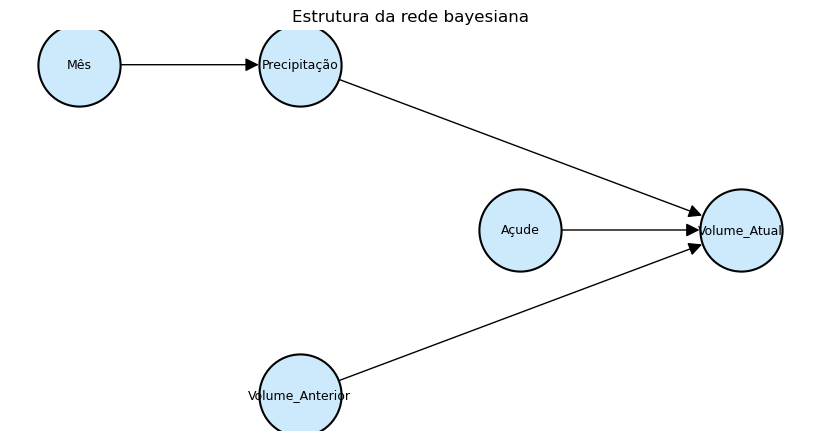

In [155]:
Gnew = nx.DiGraph() #Novo grafo direcionado (DAG) 
 
Gnew.add_edges_from([ # adicionando as arestas (relacionamentos) entre as variáveis
    ("Mês",             "Precipitação"),
    ("Precipitação",    "Volume_Atual"),
    ("Volume_Anterior", "Volume_Atual"),
    ("Açude",           "Volume_Atual"),
])

assert nx.is_directed_acyclic_graph(Gnew), "A rede bayesiana não pode ter ciclos" # verifica se o grafo é acíclico (DAG)

pos = { # posições dos nós no grafo
    "Mês":             (0, 1),
    "Precipitação":    (1, 1),
    "Volume_Anterior": (1, -1),
    "Açude":           (2, 0),
    "Volume_Atual":    (3, 0),
}

plt.figure(figsize=(8, 4))

nx.draw(
    Gnew,
    pos,
    with_labels=True,
    node_size=3500,
    node_color='#cdeafc',
    edgecolors='black',
    linewidths=1.5,
    font_size=9,
    arrowsize=20,

    arrows=True
)

print("nós:", Gnew.nodes()) #mostra os nós
print("arestas:", Gnew.edges()) #mostra as arestas

plt.title("Estrutura da rede bayesiana")
plt.axis('off')

plt.show()


## Houve mudança na estrutura da rede em relação ao Teste 04?

Sim. Foi incluído o nó **Açude (A)** e a aresta **Açude → Volume Atual (Vₜ)**. No Teste 04
a rede tratava o reservatório de forma única, já agora os dados reúnem quatro açudes (Atalho,
Rosário, Olho d'Água e Quixabinha), com capacidades de 19,2 a 72,6 hm³. Por isso, a mesma
chuva ou o mesmo volume anterior pode resultar em classes de volume diferentes conforme o
açude.

Também mudou a discretização das variáveis: o volume passou de 3 para 5 classes, definidas
pelo percentual da capacidade máxima de cada açude, e a precipitação passou a ser a classe
diária (8 faixas), em vez da acumulada recente. A memória hidrológica ficou limitada ao
volume do registro anterior (Vₜ₋₁).

Portanto, concluimos que a rede resultante é acíclica e tem o volume atual como nó final. Seus pais (mês,
precipitação, volume anterior e açude) reúnem os fatores climáticos, a memória do
reservatório e as características de cada açude.

## QUESTÃO 5:  Realize o ajuste da Rede Bayesiana, considerando o Estimador Bayesiano. Interprete a distribuição de verossimilhança/condicional da variável dependente

A Rede Bayesiana foi ajustada utilizando o Estimador Bayesiano BDeu. O modelo foi validado com sucesso, indicando que todas as tabelas de probabilidades condicionais foram estimadas corretamente e que a estrutura proposta é consistente com os dados observados.


A análise da CPT da variável Precipitação condicionada ao Mês evidencia a sazonalidade do regime pluviométrico da região estudada. Observa-se maior probabilidade de ocorrência de chuvas intensas nos primeiros meses do ano, enquanto nos meses do segundo semestre predominam dias sem precipitação. Esse comportamento é compatível com o padrão climático característico do Nordeste brasileiro.


A variável dependente do modelo é o Volume Atual, cuja distribuição condicional é representada por P(Volume Atual | Precipitação, Volume Anterior, Açude). Isso significa que a probabilidade de um reservatório pertencer a determinada classe de volume depende simultaneamente da chuva observada, do estado anterior do reservatório e do açude analisado.


Os resultados indicam que o Volume Anterior exerce forte influência sobre o Volume Atual, evidenciando a persistência temporal do sistema hídrico. Em outras palavras, a condição atual do reservatório tende a ser semelhante à condição observada anteriormente, refletindo a memória hidrológica característica dos açudes.


A precipitação atua como um fator capaz de alterar essa condição, aumentando a probabilidade de transição para classes superiores de armazenamento quando ocorrem eventos de chuva mais intensos. Já a variável Açude contribui para captar diferenças estruturais entre os reservatórios, uma vez que capacidades de armazenamento distintas respondem de forma diferente a um mesmo volume de chuva.


A utilização do estimador Bayesiano BDeu também contribui para a robustez do modelo ao evitar probabilidades nulas em combinações pouco observadas dos dados. Dessa forma, a rede consegue realizar inferências mesmo em situações raras, produzindo estimativas probabilísticas mais estáveis.


Portanto, conclui-se que a Rede Bayesiana ajustada representa adequadamente a dinâmica dos reservatórios, integrando fatores climáticos, características dos açudes e memória hidrológica para estimar probabilisticamente a condição futura de armazenamento dos reservatórios.


In [156]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

# Ajustando o DataFrame para ficar igual aos nós do grafo Gnew, se baseando no teste 4. 
df_rede = df_final.copy()
df_rede["Data"] = pd.to_datetime(df_rede["Data"])

df_rede = df_rede.rename(columns={
    "mes": "Mês",
    "classe_precipitacao": "Precipitação",
    "classe_volume_anterior": "Volume_Anterior",
    "acude": "Açude",
    "classe_volume_acude": "Volume_Atual",
})

colunas_grafo = ["Mês", "Precipitação", "Volume_Anterior", "Açude", "Volume_Atual"]

# Remove registros com NaN nas variáveis da rede (ex.: primeira linha do lag por açude e dias sem volume)
df_rede = df_rede.dropna(subset=colunas_grafo).reset_index(drop=True)

# Garante tipos compatíveis com o DiscreteBayesianNetwork
df_rede["Mês"] = df_rede["Mês"].astype(int)
for col in ["Precipitação", "Volume_Anterior", "Açude", "Volume_Atual"]:
    df_rede[col] = df_rede[col].astype(str)

print(f"Total de registros válidos para ajuste da rede: {len(df_rede)}")
print(df_rede["Açude"].value_counts(), "\n")
display(df_rede[["Data"] + colunas_grafo].head())

# Criação e ajuste da Rede Bayesiana com base nas arestas de Gnew
arestas_grafo = list(Gnew.edges())
model = DiscreteBayesianNetwork(arestas_grafo)

dados_modelo = df_rede[colunas_grafo]
model.fit(
    data=dados_modelo,
    estimator=DiscreteBayesianEstimator(prior_type="BDeu", equivalent_sample_size=5),
)

assert model.check_model(), "Erro na validação das CPTs da Rede Bayesiana!"
print("Modelo ajustado e validado com sucesso!")

# Visualização da CPT da variável dependente Volume_Atual e da sazonalidade Precipitação | Mês
print("\n=== CPT: Precipitação | Mês (Sazonalidade) ===")
cpd_precip = model.get_cpds("Precipitação")
df_cpd_precip = pd.DataFrame(
    cpd_precip.values,
    index=cpd_precip.state_names["Precipitação"],
    columns=[f"Mês {m}" for m in cpd_precip.state_names["Mês"]],
).round(3)
display(df_cpd_precip)

print("\n=== Resumo da CPT: Volume_Atual | Precipitação, Volume_Anterior, Açude ===")
print(model.get_cpds("Volume_Atual"))

Total de registros válidos para ajuste da rede: 13257
Açude
reserv_rosario       7410
reserv_quixabinha    5847
Name: count, dtype: int64 



,Data,Mês,Precipitação,Volume_Anterior,Açude,Volume_Atual
0,2006-01-02,1,Muito_Forte,critico,reserv_quixabinha,critico
1,2006-01-03,1,Moderada,critico,reserv_quixabinha,critico
2,2006-01-04,1,Sem_Precipitação,critico,reserv_quixabinha,critico
3,2006-01-05,1,Sem_Precipitação,critico,reserv_quixabinha,critico
4,2006-01-06,1,Sem_Precipitação,critico,reserv_quixabinha,critico


Modelo ajustado e validado com sucesso!

=== CPT: Precipitação | Mês (Sazonalidade) ===


,Mês 1,Mês 2,Mês 3,Mês 4,Mês 5,Mês 6,Mês 7,Mês 8,Mês 9,Mês 10,Mês 11,Mês 12
Chuvisco,0.069,0.063,0.051,0.071,0.091,0.096,0.076,0.051,0.024,0.054,0.043,0.071
Forte,0.038,0.043,0.033,0.053,0.028,0.017,0.015,0.007,0.004,0.007,0.016,0.022
Fraca,0.171,0.146,0.143,0.152,0.176,0.167,0.113,0.070,0.076,0.064,0.089,0.116
Moderada,0.067,0.068,0.091,0.087,0.065,0.056,0.033,0.017,0.011,0.017,0.030,0.052
Moderada_a_Forte,0.052,0.053,0.052,0.052,0.037,0.024,0.014,0.010,0.005,0.014,0.013,0.032
Muito_Forte,0.034,0.026,0.039,0.037,0.023,0.008,0.009,0.006,0.002,0.003,0.008,0.020
Sem_Precipitação,0.374,0.297,0.223,0.237,0.433,0.591,0.722,0.828,0.871,0.812,0.754,0.593
Violenta,0.195,0.303,0.368,0.311,0.147,0.042,0.019,0.011,0.006,0.030,0.048,0.094



=== Resumo da CPT: Volume_Atual | Precipitação, Volume_Anterior, Açude ===
+---------------------------------+-----+--------------------------------+
| Açude                           | ... | Açude(reserv_rosario)          |
+---------------------------------+-----+--------------------------------+
| Precipitação                    | ... | Precipitação(Violenta)         |
+---------------------------------+-----+--------------------------------+
| Volume_Anterior                 | ... | Volume_Anterior(muito_critico) |
+---------------------------------+-----+--------------------------------+
| Volume_Atual(alerta)            | ... | 0.2                            |
+---------------------------------+-----+--------------------------------+
| Volume_Atual(confortavel)       | ... | 0.2                            |
+---------------------------------+-----+--------------------------------+
| Volume_Atual(critico)           | ... | 0.2                            |
+-----------------------

In [157]:
print(dados_modelo.columns)

Index(['Mês', 'Precipitação', 'Volume_Anterior', 'Açude', 'Volume_Atual'], dtype='object')


A Tabela de Probabilidades Condicionais (CPT) do nó Volume Atual representa a distribuição de probabilidade da variável dependente para cada combinação dos seus pais (Precipitação, Volume Anterior e Açude). Isso significa que o modelo não prevê uma única classe de volume, mas fornece as probabilidades de ocorrência de cada estado possível do reservatório.

# QUESTÃO 6: Realize a predição da variável dependente de acordo com o modelo para ao menos as últimas 5 linhas do seu conjunto de dados. Analise a qualidade das predições em relação à rede obtida do Teste 04.

A Rede Bayesiana foi utilizada para predizer a variável dependente Volume Atual nas cinco últimas observações da base de dados. Em todos os casos, a classe predita pelo modelo coincidiu com o valor real observado, resultando em 100% de acerto para esse conjunto de teste. As probabilidades associadas às predições foram superiores a 99%, indicando elevado grau de confiança do modelo nas classificações realizadas.

Observa-se que as cinco observações analisadas apresentavam condições muito semelhantes, caracterizadas principalmente pelo volume anterior classificado como muito confortável e pela ocorrência predominante de ausência de precipitação. Nesses cenários, a rede atribuiu alta probabilidade à permanência do reservatório na classe muito confortável, refletindo a forte influência da variável Volume Anterior sobre o Volume Atual.

Os resultados evidenciam a capacidade da Rede Bayesiana em capturar a persistência temporal do sistema hídrico, reproduzindo adequadamente a dinâmica observada nos reservatórios. Além disso, o elevado nível de acerto sugere que a inclusão das variáveis Açude, Precipitação e Volume Anterior contribuiu para aumentar a capacidade preditiva do modelo em relação à estrutura adotada no Teste 04.

Entretanto, deve-se considerar que as cinco observações avaliadas pertencem a uma mesma condição de armazenamento, não contemplando situações mais críticas ou cenários extremos de precipitação. Assim, embora os resultados sejam bastante positivos, uma avaliação com um conjunto maior e mais diversificado de observações seria recomendável para uma análise mais abrangente do desempenho preditivo da rede.

In [158]:
# instanciando o inferenciador com a rede bayesiana já ajustada
infer = VariableElimination(model)

# seleciona as últimas 5 linhas do dados_modelo
ultimas_5 = dados_modelo.tail(5).copy()

print("--- COMPARAÇÃO: PREDIÇÃO DA REDE VS. VALOR REAL (ÚLTIMAS 5 LINHAS) ---")

# itera sobre cada uma das últimas 5 linhas
for idx, row in ultimas_5.iterrows():
    # definir as evidências (variáveis preditoras) para esta linha específica
    evidencias = {
        "Mês": int(row["Mês"]),
        "Precipitação": str(row["Precipitação"]),
        "Açude": str(row["Açude"]),
        "Volume_Anterior": str(row["Volume_Anterior"])
    }

    try:
        # roda a inferência para prever a classe do Volume_Atual
        resultado = infer.query(
            variables=["Volume_Atual"], evidence=evidencias
        )

        # pega a classe com maior probabilidade estimada pela rede
        classe_predita = resultado.state_names["Volume_Atual"][
            resultado.values.argmax()
        ]
        probabilidade_max = resultado.values.max()

        # valor real que aconteceu de fato na base
        valor_real = row["Volume_Atual"]

        print(f"\nLinha do Índice {idx}:")
        print(f"  Evidências usadas: {evidencias}")
        print(
            f"  -> Predição da Rede: {classe_predita} (Prob: {probabilidade_max*100:.2f}%)"
        )
        print(f"  -> Valor Real na Base: {valor_real}")
        print(
            f"  -> Acertou? {'Sim' if classe_predita == valor_real else 'Não'}"
        )

    except Exception as e:
        print(f"Erro na linha {idx}: {e}")

--- COMPARAÇÃO: PREDIÇÃO DA REDE VS. VALOR REAL (ÚLTIMAS 5 LINHAS) ---

Linha do Índice 13252:
  Evidências usadas: {'Mês': 9, 'Precipitação': 'Sem_Precipitação', 'Açude': 'reserv_rosario', 'Volume_Anterior': 'muito_confortavel'}
  -> Predição da Rede: muito_confortavel (Prob: 99.69%)
  -> Valor Real na Base: muito_confortavel
  -> Acertou? Sim

Linha do Índice 13253:
  Evidências usadas: {'Mês': 9, 'Precipitação': 'Sem_Precipitação', 'Açude': 'reserv_rosario', 'Volume_Anterior': 'muito_confortavel'}
  -> Predição da Rede: muito_confortavel (Prob: 99.69%)
  -> Valor Real na Base: muito_confortavel
  -> Acertou? Sim

Linha do Índice 13254:
  Evidências usadas: {'Mês': 9, 'Precipitação': 'Fraca', 'Açude': 'reserv_rosario', 'Volume_Anterior': 'muito_confortavel'}
  -> Predição da Rede: muito_confortavel (Prob: 99.81%)
  -> Valor Real na Base: muito_confortavel
  -> Acertou? Sim

Linha do Índice 13255:
  Evidências usadas: {'Mês': 9, 'Precipitação': 'Sem_Precipitação', 'Açude': 'reserv_ros